# 02 · Preparación de los datos (CRISP-DM fase 3)

**Objetivo:** verificar cada paso del pipeline de preparación y mostrar qué produce:

1. deduplicación y partición agrupada (sin fuga entre conjuntos);
2. recorte central y redimensionamiento a 128×128;
3. las 418 características manuales que usan los modelos clásicos;
4. la segmentación de la fruta y la estimación del tamaño;
5. la segmentación de la carpeta *Mixed* en frutas individuales.

El detalle y la justificación de cada decisión están en `docs/crisp-dm/03_preparacion_datos.md`.

In [1]:
import os
from pathlib import Path
if Path.cwd().name == "notebooks":
    os.chdir("..")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from PIL import Image, ImageOps
from skimage.feature import hog, local_binary_pattern
from src.utils.paths import MANIFEST_PATH, SPLITS_PATH, RAW_DATASET, INTERIM
from src.utils import plotting
from src.evaluation.metrics import FRUITS, FRUIT_ES
from src.data.preprocess import load_split, square_resize
from src.data.segment_mixed import fruit_components, WORK_SIZE
from src.features.handcrafted import features_path, feature_names
from src.features.size import estimate_size, SIZE_THRESHOLDS
plotting.setup()
man = pd.read_csv(MANIFEST_PATH)
splits = pd.read_csv(SPLITS_PATH)

## 1. Deduplicación y partición agrupada

Se conserva **una imagen por captura** (la original) y se reparte por **ráfagas** (fotos tomadas en la misma ventana de 60 s) con `StratifiedGroupKFold`. Se verifica que:

- ninguna ráfaga aparezca en dos conjuntos;
- ninguna captura (ni su hash md5) se repita entre conjuntos;
- cada conjunto conserve la proporción de las 12 clases.

In [2]:
print(f"Archivos: {len(man):,} -> imágenes únicas: {len(splits):,}")
lab = splits[splits.split != "mixed"]
g = lab.groupby("group").split.nunique()
print("Ráfagas repartidas en más de un conjunto:", int((g > 1).sum()))
print("Hashes md5 repetidos entre conjuntos:", int((lab.groupby("md5").split.nunique() > 1).sum()))
tab = pd.crosstab(lab.label, lab.split)[["train", "val", "test"]]
tab.loc["TOTAL"] = tab.sum()
(tab.assign(**{"% test": (100 * tab.test / tab.sum(axis=1)).round(1)}))

Archivos: 19,526 -> imágenes únicas: 12,185
Ráfagas repartidas en más de un conjunto: 0
Hashes md5 repetidos entre conjuntos: 0


split,train,val,test,% test
label,,,,
apple_bad,570,114,115,14.4
apple_good,809,161,162,14.3
banana_bad,568,113,113,14.2
banana_good,780,156,156,14.3
guava_bad,541,115,107,14.0
guava_good,803,160,161,14.3
lime_bad,673,135,135,14.3
lime_good,571,117,113,14.1
orange_bad,593,118,119,14.3


La partición queda en ≈ 72 / 14 / 14 % y todas las clases tienen ≈ 14 % de sus imágenes en prueba. Las 873 imágenes de *Mixed* no se usan para entrenar: se reservan para la evaluación cualitativa (sección 5).

## 2. Recorte central y redimensionamiento

Se corrige la orientación EXIF, se recorta el cuadrado central de lado $\min(H, W)$ y se reduce a 128×128 por promedio de área. La fruta no se deforma y se descarta parte del fondo.

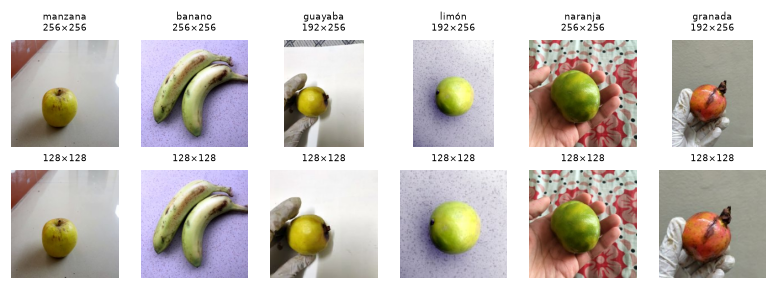

In [3]:
ej = lab.groupby("fruit").sample(1, random_state=3)
fig, axes = plt.subplots(2, 6, figsize=(7.2, 2.7))
for k, (_, r) in enumerate(ej.iterrows()):
    img = ImageOps.exif_transpose(Image.open(RAW_DATASET / r.path)).convert("RGB")
    axes[0, k].imshow(img); axes[0, k].set_title(f"{FRUIT_ES[r.fruit]}\n{img.width}×{img.height}", fontsize=6)
    axes[1, k].imshow(square_resize(img)); axes[1, k].set_title("128×128", fontsize=6)
for a in axes.ravel():
    a.axis("off")
fig.tight_layout()

## 3. Características manuales (418 dimensiones)

| Bloque | Dim. | Qué captura |
|---|---|---|
| Histogramas HSV | 34 | distribución de tono, saturación y brillo |
| Momentos de color HSV y Lab | 18 | media, desviación y asimetría por canal |
| Proporción de píxeles oscuros y marrones | 2 | manchas y podredumbre |
| LBP uniforme (2 radios) | 28 | microtextura de la cáscara |
| GLCM | 12 | contraste, homogeneidad, energía, correlación… |
| HOG | 324 | forma y bordes |

A continuación se visualiza qué "ve" cada bloque en una fruta buena y una mala.

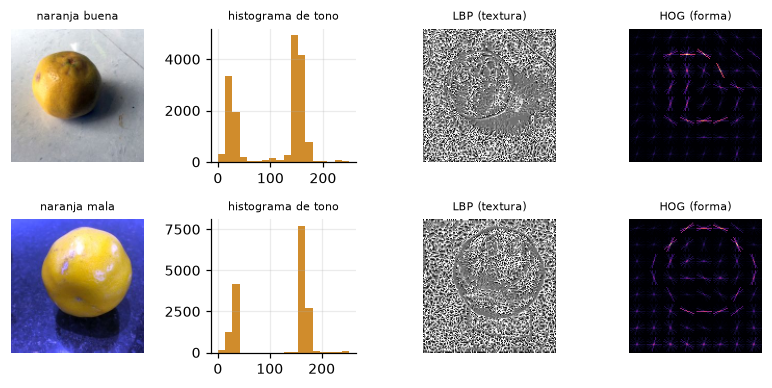

In [4]:
Xtr, mtr = load_split("train", splits)
pair = [mtr[(mtr.fruit == "orange") & (mtr.quality == q)].index[0] for q in ("good", "bad")]
fig, axes = plt.subplots(2, 4, figsize=(7.2, 3.6))
for row, i in enumerate(pair):
    img = Xtr[i]
    gray = np.asarray(Image.fromarray(img).convert("L"))
    hsv = np.asarray(Image.fromarray(img).convert("HSV"))
    axes[row, 0].imshow(img); axes[row, 0].set_title(f"naranja {'buena' if row == 0 else 'mala'}", fontsize=7)
    axes[row, 1].hist(hsv[..., 0].ravel(), 18, color="#d08c2c"); axes[row, 1].set_title("histograma de tono", fontsize=7)
    axes[row, 2].imshow(local_binary_pattern(gray, 8, 1, "uniform"), cmap="gray"); axes[row, 2].set_title("LBP (textura)", fontsize=7)
    _, hv = hog(gray, orientations=9, pixels_per_cell=(16, 16), cells_per_block=(2, 2), visualize=True)
    axes[row, 3].imshow(hv, cmap="magma"); axes[row, 3].set_title("HOG (forma)", fontsize=7)
for a in axes[:, [0, 2, 3]].ravel():
    a.axis("off")
fig.tight_layout()

In [5]:
F = np.load(features_path("train"))
X = F["X"] if "X" in F.files else F[F.files[0]]
names = feature_names()
print("Matriz de entrenamiento:", X.shape, "| nombres:", len(names))
df = pd.DataFrame(X[:, :52], columns=names[:52]).assign(calidad=mtr.quality.values)
# Diferencia estandarizada (d de Cohen) entre buenas y malas: qué características de color separan más
g, b = df[df.calidad == "good"].drop(columns="calidad"), df[df.calidad == "bad"].drop(columns="calidad")
d = ((g.mean() - b.mean()) / np.sqrt((g.var() + b.var()) / 2)).sort_values(key=abs, ascending=False)
d.head(10).round(2).to_frame("d de Cohen (buena − mala)")

Matriz de entrenamiento: (8078, 418) | nombres: 418


,d de Cohen (buena − mala)
lab_skew_1,-1.10
sat_0,-0.69
lab_std_2,0.68
lab_mean_0,-0.63
lab_skew_0,0.63
hsv_skew_2,0.62
val_3,0.60
hsv_mean_2,-0.60
hue_1,-0.59
lab_std_1,0.57


Ninguna característica de color separa por sí sola las dos calidades (|d| ≤ 1,1), lo que justifica combinar cientos de ellas en un modelo no lineal. Las de mayor separación son la asimetría del canal a* (rojo–verde), la fracción de píxeles poco saturados, la dispersión en b* (amarillo–azul) y la luminosidad L*. El signo negativo de `lab_mean_0` indica que las imágenes de frutas malas son, en promedio, **más claras**: no es un rasgo de la fruta sino del fondo con que se fotografiaron (fase 2). La fase 5 cuantifica ese sesgo con un modelo entrenado **solo** con el borde de la imagen.

## 4. Segmentación y tamaño

Pipeline (`src/features/size.py`): color de fondo = mediana del borde en Lab → distancia de cada píxel al fondo → umbral de Otsu → apertura y cierre → componente más grande → $d_{norm} = 2\sqrt{A/\pi}/\min(H,W)$.

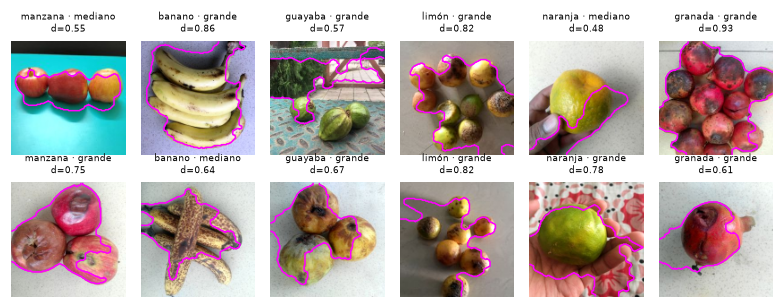

In [6]:
Xte, mte = load_split("test", splits)
ej = mte.groupby("fruit").sample(2, random_state=1)
fig, axes = plt.subplots(2, 6, figsize=(7.2, 2.8))
for a, (i, r) in zip(axes.T.ravel(), ej.iterrows()):
    s = estimate_size(Xte[i], r.fruit)
    a.imshow(Xte[i]); a.contour(s.mask, levels=[0.5], colors="#ff00ff", linewidths=1)
    a.set_title(f"{FRUIT_ES[r.fruit]} · {s.category}\nd={s.d_norm:.2f}", fontsize=6); a.axis("off")
fig.tight_layout()

In [7]:
sub = mte.groupby("fruit").sample(60, random_state=0)
sub["d_norm"] = [estimate_size(Xte[i], f).d_norm for i, f in zip(sub.index, sub.fruit)]
res = sub.groupby("fruit").d_norm.describe()[["mean", "25%", "50%", "75%"]].round(2)
res["umbrales (peq/med, med/gra)"] = [SIZE_THRESHOLDS[f] for f in res.index]
res

,mean,25%,50%,75%,"umbrales (peq/med, med/gra)"
fruit,,,,,
apple,0.62,0.50,0.62,0.75,"(0.4, 0.55)"
banana,0.63,0.54,0.60,0.71,"(0.45, 0.65)"
guava,0.62,0.53,0.63,0.70,"(0.35, 0.5)"
lime,0.56,0.42,0.55,0.67,"(0.22, 0.32)"
orange,0.62,0.55,0.61,0.69,"(0.4, 0.55)"
pomegranate,0.65,0.53,0.66,0.76,"(0.42, 0.58)"


En el dataset la distancia de la cámara no está controlada (hay fotos de una fruta en la mano y de varias en el piso), así que $d_{norm}$ varía mucho dentro de cada fruta. Por eso el tamaño es **relativo** y los umbrales iniciales se recalibran con las fotos propias, tomadas a ~30 cm según el protocolo de `data/own/README.md` (`calibrate_thresholds` usa los terciles). Es una limitación declarada: sin una referencia de escala (una moneda o una cuadrícula), no se puede medir el tamaño en centímetros.

## 5. Segmentación de la carpeta *Mixed*

Las fotos de *Mixed* tienen varias frutas y no tienen etiqueta de calidad. Se separan así: color de fondo = grupo de color más grande (k-means en Lab), distancia al fondo con la luminosidad con peso 0,3 (ignora sombras), Otsu y morfología, **watershed** sobre la transformada de distancia para separar frutas que se tocan y filtros de forma (no tocar el borde, área 0,4–25 %, solidez ≥ 0,85, aspecto ≤ 3). Cada recorte queda listo para que el equipo lo anote con `streamlit run src/app/annotate.py`.

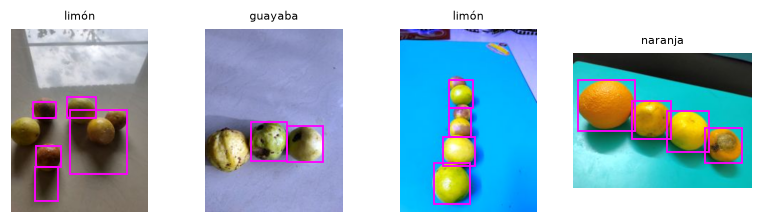

In [8]:
mixed = splits[splits.split == "mixed"].sample(4, random_state=5)
fig, axes = plt.subplots(1, 4, figsize=(7.2, 2.1))
for a, (_, r) in zip(axes, mixed.iterrows()):
    img = ImageOps.exif_transpose(Image.open(RAW_DATASET / r.path)).convert("RGB")
    sc = WORK_SIZE / max(img.size)
    small = np.asarray(img.resize((round(img.width * sc), round(img.height * sc))))
    a.imshow(small)
    for (x, y, w, h) in fruit_components(small):
        a.add_patch(plt.Rectangle((x, y), w, h, fill=False, ec="#ff00ff", lw=1.2))
    a.set_title(FRUIT_ES[r.fruit], fontsize=7); a.axis("off")
fig.tight_layout()
plotting.save(fig, "prep_segmentacion_mixed")

In [9]:
ann = pd.read_csv(INTERIM / "mixed_crops" / "annotation.csv")
print(f"{splits.query('split == \"mixed\"').shape[0]} fotos Mixed -> {len(ann)} recortes")
ann.fruit.map(FRUIT_ES).value_counts().to_frame("recortes")

873 fotos Mixed -> 3640 recortes


,recortes
fruit,
limón,1166
naranja,667
granada,544
manzana,506
guayaba,385
banano,372


**Resumen.** Los datos quedan sin fuga entre conjuntos, con tamaño homogéneo, con un vector de 418 características por imagen para el ML clásico y con imágenes normalizadas para la CNN. La segmentación da el tamaño relativo y convierte *Mixed* en recortes individuales evaluables.